# Ancient Environmental Metagenomics (AEMG01)
## Day 2 · Practical: Read-based taxonomic profiling and reference databases

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day2_TaxonomicProfiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisites:** `Day1_setup.ipynb` (shortcut to the shared folder, `course_paths.json`) and `Day1_QC.ipynb` (human-free reads in `04_HOST_REMOVAL/`).

### Learning outcomes
After this practical you will be able to:

* explain how **k-mer-based classifiers** (KrakenUniq, Kraken2) assign reads to taxa using the **lowest common ancestor (LCA)**,
* run **KrakenUniq** and read its report, including the **number of unique k-mers** – a proxy for breadth of coverage,
* filter taxonomic profiles on **depth** *and* **breadth** of coverage to remove false-positive hits,
* build a **samples × species abundance matrix** and visualise it (heatmap, Krona, Pavian),
* run **Kraken2** with distinct-minimizer reporting and **sourmash** (FracMinHash, GTDB) and compare the tools,
* **build your own Kraken2 database** and see how the **k-mer size** and the **database content** change the result,
* follow up a k-mer hit with an alignment in **IGV**.

<p align="center">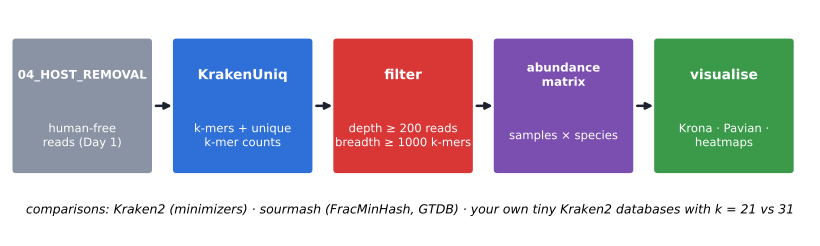<br><em>Today's workflow. Results go to 05_TAXONOMIC_PROFILE, 06_KRAKENUNIQ_ABUNDANCE_MATRIX and 05b_CUSTOM_DB in your Drive.</em></p>

---
## Scientific background: "Who is there?"

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/metagenomic_approaches.png" width="680"><br><em>Three ways to find out which organisms are present: alignment to reference genomes, k-mer-based classification, and de-novo assembly.</em></p>

There are three main ways to identify organisms in a metagenome:

| Approach | Examples | Strengths | Weaknesses |
|---|---|---|---|
| **Alignment** of reads to reference genomes | Bowtie2, BWA, MALT | base-level detail: mismatches, damage, coverage | slow and memory-hungry for large databases |
| **k-mer-based classification** | Kraken, KrakenUniq, Kraken2, Centrifuge, MetaPhlAn | very fast, can screen against **all** known microbes | no alignment, so no damage pattern or edit distance |
| **De-novo assembly** | MEGAHIT, metaSPAdes | reference-free: finds organisms not in any database | hard with short, low-coverage aDNA |

Alignment and classification are **reference-based**: they assume an ancient read resembles a modern reference genome. In practice the standard strategy (used, for example, in the aMeta workflow) is:

1. **screen** all reads quickly against a very large database with a k-mer classifier (**today**),
2. **filter** the hits on depth and breadth of coverage,
3. **follow up** the remaining candidates with alignments and authenticate them (evenness of coverage, damage, edit distance – **Day 3**).

### How a k-mer classifier works

<p align="center">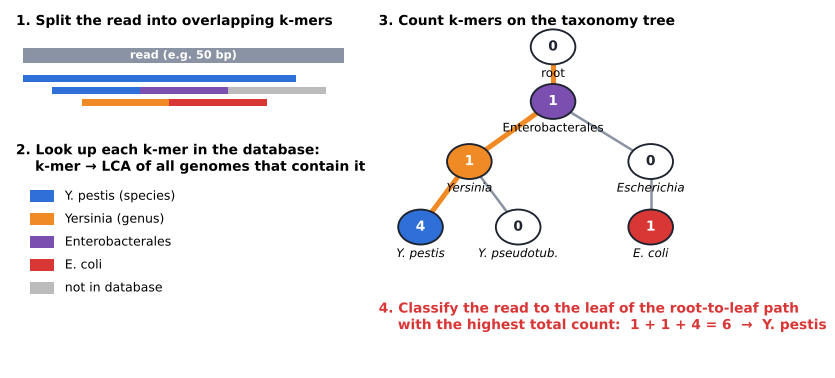<br><em>Kraken-style classification: every k-mer of a read is looked up in a database that maps k-mers to the lowest common ancestor (LCA) of all genomes containing them.</em></p>

A **k-mer** is a substring of length *k*. A read of length *L* contains *L − k + 1* overlapping k-mers. The database is built in advance: every k-mer of every reference genome is stored together with the **lowest common ancestor (LCA)** of all genomes in which it occurs. A k-mer unique to *Yersinia pestis* maps to the species; a k-mer shared by *Y. pestis* and *Y. pseudotuberculosis* maps to the genus *Yersinia*; a k-mer found in many bacteria maps high up in the tree.

To classify a read, every k-mer is looked up, the hits are placed on the taxonomy tree and the read is assigned to the leaf of the **root-to-leaf path with the most hits**. Reads whose k-mers point to different branches end up at a higher, less specific rank (the LCA). Reads with no k-mer in the database are **unclassified**.

There is no alignment, only exact hash-table lookups – that's why classifiers can screen millions of reads against tens of thousands of genomes in minutes.

---
## 1. Session setup

As every day: (1) conda, (2) Google Drive, (3) today's software, (4) paths and helpers.

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

In [ ]:
import condacolab
condacolab.check()

### 1.2 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### 1.3 Install today's software

| Tool | What we use it for | Installed with |
|---|---|---|
| [KrakenUniq](https://github.com/fbreitwieser/krakenuniq) | k-mer classification + **unique k-mer** counting | mamba (Bioconda) |
| [Kraken2](https://github.com/DerrickWood/kraken2) | minimizer-based classification, custom database building | mamba (Bioconda) |
| [Krona](https://github.com/marbl/Krona) | interactive pie charts of taxonomic profiles | mamba (Bioconda) |
| [Bowtie2](https://bowtie-bio.sourceforge.net/bowtie2/), [samtools](http://www.htslib.org/) | follow-up alignment of a hit | mamba (Bioconda) |
| [sourmash](https://sourmash.readthedocs.io/) | FracMinHash sketching and `gather` | pip |
| [igv-notebook](https://github.com/igvteam/igv-notebook) | IGV genome browser inside the notebook | pip |

We install sourmash from PyPI (`pip`) instead of conda; it ships ready-made binary wheels, and keeping it out of the conda solve makes installation faster and avoids version conflicts with Colab's Python. Installation output goes to `/content/install.log`.

In [ ]:
!mamba install -y -q -c conda-forge -c bioconda krakenuniq kraken2 krona bowtie2 samtools > /content/install.log 2>&1
!pip install -q sourmash igv-notebook

In [ ]:
%%bash
krakenuniq --version 2>&1 | head -1
kraken2 --version | head -1
sourmash --version
bowtie2 --version | head -1
samtools --version | head -1
echo "Krona: $(which ktImportTaxonomy)"
echo "Rscript: $(which Rscript || echo 'not found')"

> 💡 The course helper script `krakenuniq_abundance_matrix.R` needs **R**. Colab images normally include R (`/usr/bin/Rscript`). If the line above says *not found*, run `!mamba install -y -q -c conda-forge r-base` before Section 4.

### 1.4 Paths, databases and helper functions

We read the shared-folder location from `course_paths.json` and then **look for the databases automatically**, by searching `$SHARE/Databases/` for the files that identify each database type:

| Database | Identified by | Used by |
|---|---|---|
| KrakenUniq (complete microbial NCBI RefSeq) | `database.kdb` | `krakenuniq --db` |
| MiniKraken2 v2 (8 GB) | `hash.k2d` | `kraken2 --db` |
| sourmash GTDB rs207 | `*.k31.zip` and `*taxonomy*.csv.gz` | `sourmash gather` / `sourmash tax` |

This way the notebook works whatever the exact folder names are (e.g. `Databases/KrakenUniq` or `Databases/KrakenUniq_DB`). If a path is printed as `None`, set it manually.

In [ ]:
import os, json, glob

WORKDIR = "/content/drive/MyDrive/AncientEnvironmentalMetagenomics"
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
DBS = f"{SHARE}/Databases"

def find_dir_containing(filename, root=DBS, max_depth=3):
    """Return the first folder under root (searching max_depth levels) that contains filename."""
    for depth in range(1, max_depth + 1):
        hits = sorted(glob.glob(f"{root}/" + "*/" * depth + filename))
        if hits:
            return os.path.dirname(hits[0])
    return None

def find_file(pattern, root=DBS, max_depth=3):
    for depth in range(1, max_depth + 1):
        hits = sorted(glob.glob(f"{root}/" + "*/" * depth + pattern))
        if hits:
            return hits[0]
    return None

KRAKENUNIQ_DB = find_dir_containing("database.kdb")
KRAKEN2_DB    = find_dir_containing("hash.k2d")
SOURMASH_DB   = find_file("*genomic-reps*k31*.zip") or find_file("*.k31.zip")
SOURMASH_TAX  = find_file("*taxonomy*.csv.gz")
SCRIPTS       = f"{SHARE}/scripts"

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, THREADS=str(os.cpu_count()),
                  KRAKENUNIQ_DB=str(KRAKENUNIQ_DB), KRAKEN2_DB=str(KRAKEN2_DB),
                  SOURMASH_DB=str(SOURMASH_DB), SOURMASH_TAX=str(SOURMASH_TAX), SCRIPTS=SCRIPTS)
os.chdir(WORKDIR)

for k in ["WORKDIR", "SHARE", "KRAKENUNIQ_DB", "KRAKEN2_DB", "SOURMASH_DB", "SOURMASH_TAX", "SCRIPTS", "THREADS"]:
    print(f"{k:14s}: {os.environ[k]}")

SAMPLES = open("SAMPLES.txt").read().split()
missing = [s for s in SAMPLES if not os.path.exists(f"04_HOST_REMOVAL/{s}_unaligned_to_hg38.fastq.gz")]
print("\nHuman-free reads from Day 1:", "✅ all present" if not missing else f"❌ missing for {missing} – run Day1_QC.ipynb first")

The same three helpers as on Day 1, for showing HTML reports (here: **Krona** charts) inside the notebook: `show_html(path)` (interactive, via a small local web server), `show_html_inline(path)` (fallback) and `download(path)`.

In [ ]:
import subprocess, socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown
import pandas as pd, numpy as np, matplotlib.pyplot as plt

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_html(path, height=800):
    """Show an HTML file (path relative to WORKDIR) in an interactive iframe."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", WORKDIR],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + path, height=height)

def show_html_inline(path):
    display(HTML(open(path).read()))

def download(path):
    files.download(path)

pd.set_option("display.max_rows", 60)
print("Helpers ready")

---
## 2. Taxonomic profiling with KrakenUniq

### Background
[**KrakenUniq**](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-018-1568-0) (Breitwieser et al. 2018) is Kraken 1 (k = 31) with one crucial addition for ancient metagenomics: for every taxon it also counts **how many *different* (unique) k-mers** of that taxon were seen in the sample. It does this memory-efficiently with the **HyperLogLog** algorithm, a probabilistic counter that estimates the number of distinct items using a few kilobytes per taxon.

Why does that matter? The number of reads assigned to a taxon (**depth** of coverage) can be high for the wrong reasons: e.g. reads of an unknown organism that share one conserved gene (ribosomal RNA operons, mobile elements) with a reference genome all pile up on that one locus. The number of **unique k-mers** tells us how much of the genome those reads cover (**breadth** of coverage):

<p align="center">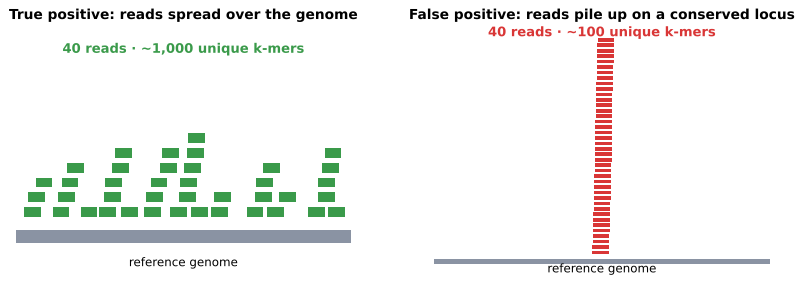<br><em>Same number of reads, very different conclusions: unique k-mers distinguish reads spread over a genome (true positive) from reads stacked on one conserved region (likely false positive).</em></p>
<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/depth_vs_breadth_of_coverage.png" width="620"><br><em>Depth vs breadth of coverage.</em></p>

### The database
The pre-built KrakenUniq database contains complete microbial genomes (bacteria, archaea, viruses, fungi, protozoa) from NCBI RefSeq plus the human genome; it is publicly available at [https://doi.org/10.17044/scilifelab.21299541](https://doi.org/10.17044/scilifelab.21299541) and has been placed in the shared folder:

```bash
# DO NOT RUN (ALREADY DONE)
wget https://figshare.scilifelab.se/ndownloader/articles/21299541/versions/1 && unzip 1 && rm 1
```

A KrakenUniq database folder contains `database.kdb` (the k-mer → LCA table, sorted), `database.idx` (an index into it), `taxDB` (the taxonomy) and `database.kdb.counts` (number of unique k-mers per taxon in the database, used to compute coverage).

In [ ]:
!ls -lh $KRAKENUNIQ_DB

### Run KrakenUniq

| Flag | Meaning |
|---|---|
| `--db $KRAKENUNIQ_DB` | the database folder |
| `--fastq-input` | the input is FASTQ (not FASTA); gzip is detected automatically |
| `04_HOST_REMOVAL/${sample}_unaligned_to_hg38.fastq.gz` | the human-free reads from Day 1 (the last, positional argument; in the original course text it was written right after `--fastq-input`) |
| `--threads $THREADS` | CPU cores |
| `--classified-out` / `--unclassified-out` | write the reads that were / were not classified into separate files (useful for e.g. de-novo assembling the unclassified fraction) |
| `--output` | the **per-read** classification table (one line per read) |
| `--report-file` | the **per-taxon** summary report – the main result |

The first sample is slow because the database has to be loaded from Drive into memory; KrakenUniq keeps it cached by the operating system for the following samples.

> 💡 **Low on memory?** KrakenUniq can process a database larger than the available RAM in chunks with `--preload-size 8G` (load 8 GB at a time). This is slower, but it lets you use a huge database on a small machine.

In [ ]:
%%bash
cd $WORKDIR
mkdir -p 05_TAXONOMIC_PROFILE

for sample in $(cat SAMPLES.txt); do
  echo "$(date +%H:%M:%S)  KrakenUniq: ${sample}"
  krakenuniq --db $KRAKENUNIQ_DB \
    --fastq-input 04_HOST_REMOVAL/${sample}_unaligned_to_hg38.fastq.gz \
    --threads $THREADS \
    --classified-out   05_TAXONOMIC_PROFILE/${sample}.classified_sequences.krakenuniq \
    --unclassified-out 05_TAXONOMIC_PROFILE/${sample}.unclassified_sequences.krakenuniq \
    --output           05_TAXONOMIC_PROFILE/${sample}.sequences.krakenuniq \
    --report-file      05_TAXONOMIC_PROFILE/${sample}.krakenuniq.output \
    2> 05_TAXONOMIC_PROFILE/${sample}.krakenuniq.log
  tail -n 3 05_TAXONOMIC_PROFILE/${sample}.krakenuniq.log
done

### The per-read output

Each line of `*.sequences.krakenuniq` describes one read:

| Column | Example | Meaning |
|---|---|---|
| 1 | `C` / `U` | **C**lassified or **U**nclassified |
| 2 | `read_0001` | read ID |
| 3 | `632` | the assigned NCBI taxonomy ID (0 = unclassified) |
| 4 | `52` | read length |
| 5 | `632:12 1386:3 0:7 …` | the **k-mer LCA list**: runs of consecutive k-mers and the taxon they map to (`0` = not in database, `A` = contains an ambiguous base) |

Column 5 is the "evidence" behind each assignment. You can look up any taxonomy ID at [ncbi.nlm.nih.gov/taxonomy](https://www.ncbi.nlm.nih.gov/taxonomy) (e.g. 632 = *Yersinia pestis*).

In [ ]:
%%bash
cd $WORKDIR
head -n 5 05_TAXONOMIC_PROFILE/sample10.sequences.krakenuniq | cut -c 1-200
echo
echo "classified   : $(grep -c '^C' 05_TAXONOMIC_PROFILE/sample10.sequences.krakenuniq)"
echo "unclassified : $(grep -c '^U' 05_TAXONOMIC_PROFILE/sample10.sequences.krakenuniq)"

### The KrakenUniq report

The report (`*.krakenuniq.output`) is a taxonomy tree written as a table, one taxon per line:

| Column | Meaning |
|---|---|
| `%` | percentage of all reads assigned to this taxon **and its descendants** (the *clade*) |
| `reads` | number of reads in the clade |
| `taxReads` | reads assigned **exactly** to this taxon (not to a descendant) – our **depth** metric |
| `kmers` | number of **unique k-mers** observed for the clade – our **breadth** metric |
| `dup` | average number of times each unique k-mer was seen (k-mer duplication) |
| `cov` | coverage of the taxon's k-mers in the database (`kmers` / k-mers of that taxon in the database) |
| `taxID`, `rank`, `taxName` | NCBI taxonomy ID, rank (species, genus, …) and name; the name is indented to show the tree |

Let's write a small function that reads any KrakenUniq report into a pandas data frame (lines starting with `#` are comments).

In [ ]:
def read_krakenuniq(path):
    df = pd.read_csv(path, sep="\t", comment="#", dtype={"taxID": str})
    df["taxName"] = df["taxName"].str.strip()
    return df

ku = read_krakenuniq("05_TAXONOMIC_PROFILE/sample10.krakenuniq.output")
print(ku["rank"].value_counts().head(8))
ku[ku["rank"] == "species"].sort_values("taxReads", ascending=False).head(15)

❓ **Questions**
1. What fraction of the reads of sample10 is unclassified? Why can that be expected for an ancient environmental sample?
2. Look at the top species by `taxReads`. For which of them does the number of unique k-mers look small compared to the number of reads?

---
## 3. Filtering on depth and breadth of coverage

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/krakenuniq_filter.png" width="720"><br><em>Filtering KrakenUniq output on both depth (taxReads) and breadth (unique k-mers) of coverage removes most false-positive hits.</em></p>

Unfiltered taxonomic profiles of ancient metagenomes contain **hundreds of species**, most of them false positives: reads of organisms that are missing from the database get assigned to their closest relative, short reads match by chance, and conserved regions attract reads from many taxa. We therefore keep only species that pass **both** thresholds:

* **depth:** `taxReads ≥ 200` – enough reads for downstream authentication (damage patterns need reads!),
* **breadth:** `kmers ≥ 1000` unique k-mers – the reads must come from many different places in the genome.

These are the defaults of the aMeta workflow (Pochon et al. 2023); they were chosen with simulations such as our data. For a real study, think about how the thresholds depend on sequencing depth and genome size.

### 3.1 Filtering with the course script

The script `filter_krakenuniq.py` takes four arguments: the KrakenUniq report, the minimum number of **unique k-mers** (1000), the minimum number of **taxReads** (200) and a list of **known pathogens** (`pathogensfound.very_inclusive.tab`) used to flag pathogenic species among the hits. It writes the filtered tables next to the input file.

* `cd 05_TAXONOMIC_PROFILE` – the script writes its output into the current folder,
* `for i in $(ls *.krakenuniq.output)` – loop over all reports,
* `python3 $SCRIPTS/filter_krakenuniq.py …` – we call the script through `python3` because files on Google Drive cannot be made *executable*, so running `script.py` directly would fail with *Permission denied*.

In [ ]:
%%bash
cd $WORKDIR/05_TAXONOMIC_PROFILE
for i in $(ls *.krakenuniq.output); do
  python3 $SCRIPTS/filter_krakenuniq.py $i 1000 200 $SCRIPTS/pathogensfound.very_inclusive.tab
done
cd ..
ls -lt 05_TAXONOMIC_PROFILE | head -n 15

The newest files in the listing are the script's outputs (filtered species list and the pathogens among them). Let's display everything the script produced for **sample10**:

In [ ]:
for f in sorted(glob.glob("05_TAXONOMIC_PROFILE/*")):
    if "sample10" in f and ("filtered" in f or "pathogen" in f):
        print("=" * 20, f)
        print(open(f).read()[:3000])

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/filtered_krakenuniq_output.png" width="720"><br><em>Expected result: after filtering, a Yersinia pestis hit in sample10 passes both thresholds.</em></p>

### 3.2 The same filter in pandas – and a look at *why* it works

It's worth implementing the filter ourselves: it's two lines, and it lets us **plot** depth against breadth for every species in every sample. Points in the upper-right corner pass both filters.

In [ ]:
MIN_KMERS, MIN_READS = 1000, 200

all_species = []
for s in SAMPLES:
    d = read_krakenuniq(f"05_TAXONOMIC_PROFILE/{s}.krakenuniq.output")
    d = d[d["rank"] == "species"].copy()
    d["sample"] = s
    all_species.append(d)
all_species = pd.concat(all_species)
all_species["pass"] = (all_species.kmers >= MIN_KMERS) & (all_species.taxReads >= MIN_READS)

print(f"species hits before filtering: {len(all_species)}   after: {all_species['pass'].sum()}")
display(all_species[all_species["pass"]][["sample", "taxName", "taxID", "taxReads", "kmers", "dup", "cov"]]
        .sort_values(["sample", "taxReads"], ascending=[True, False]))

plt.figure(figsize=(7, 6))
sub = all_species[all_species.taxReads > 0]
plt.scatter(sub.taxReads, sub.kmers, s=8, alpha=0.4,
            c=np.where(sub["pass"], "#D93636", "#8A93A3"))
plt.xscale("log"); plt.yscale("log")
plt.axvline(MIN_READS, ls="--", c="k"); plt.axhline(MIN_KMERS, ls="--", c="k")
plt.xlabel("taxReads (depth)"); plt.ylabel("unique k-mers (breadth)")
plt.title("All species in all samples (red = pass both filters)")
for _, r in all_species[all_species["pass"]].iterrows():
    plt.annotate(f"{r.taxName} ({r['sample']})", (r.taxReads, r.kmers), fontsize=7)
plt.show()

❓ **Questions**
1. How many species hits are removed by the filter?
2. Find species with many reads but few unique k-mers (lower right of the plot). What could these be?
3. What happens if you change `MIN_KMERS` to 500 or 5000? Re-run the cell.
4. A read of 50 bp contains 50 − 31 + 1 = 20 k-mers. If 200 such reads were spread **without overlap** over a genome, roughly how many unique k-mers would you expect? What does a ratio `kmers / taxReads` close to 1 – or much higher – tell you?

---
## 4. A samples × species abundance matrix

To compare samples we need a single table: **rows = species, columns = samples, values = number of reads**. The course R script `krakenuniq_abundance_matrix.R` builds it from all KrakenUniq reports in a folder, applying the same breadth and depth filters.

Arguments: input folder (`05_TAXONOMIC_PROFILE`), output folder (`06_KRAKENUNIQ_ABUNDANCE_MATRIX`), minimum unique k-mers (1000), minimum taxReads (200). `Rscript` runs an R script from the command line.

In [ ]:
%%bash
cd $WORKDIR
Rscript $SCRIPTS/krakenuniq_abundance_matrix.R 05_TAXONOMIC_PROFILE 06_KRAKENUNIQ_ABUNDANCE_MATRIX 1000 200
ls -lh 06_KRAKENUNIQ_ABUNDANCE_MATRIX

In [ ]:
mat = pd.read_csv("06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt", sep="\t", index_col=0)
mat

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/krakenuniq_abundance_matrix.png" width="720"><br><em>Expected abundance matrix: Yersinia pestis appears in a few samples in addition to sample10.</em></p>

A **heatmap** on a log scale makes the matrix easier to read: `log10(reads + 1)` (the `+1` avoids `log(0)`). Each row is a species, each column a sample.

In [ ]:
m = np.log10(mat.astype(float) + 1)
plt.figure(figsize=(1.0 * m.shape[1] + 4, 0.35 * m.shape[0] + 2))
plt.imshow(m, aspect="auto", cmap="viridis")
plt.colorbar(label="log10(reads + 1)")
plt.xticks(range(m.shape[1]), m.columns, rotation=90)
plt.yticks(range(m.shape[0]), m.index, fontsize=8)
plt.title("KrakenUniq abundance matrix (filtered)"); plt.tight_layout(); plt.show()

❓ **Questions** – the idea is to make sense of the community composition:
1. What are the most abundant taxa in our samples?
2. Do samples differ in community composition? Which samples are most similar?
3. In which samples, besides sample10, does *Yersinia pestis* appear? Does it pass the filters there?
4. What fraction of the reads could we identify at all (look at the unclassified percentage in each report)? There is so much that still remains unknown…

---
## 5. Visualising taxonomic profiles: Krona and Pavian

### 5.1 Krona – inside the notebook
[**Krona**](https://bmcbioinformatics.biomedcentral.com/articles/10.1186/1471-2105-12-385) draws a taxonomic profile as an interactive, zoomable multi-level pie chart (an HTML file).

1. `ktUpdateTaxonomy.sh /content/krona_taxonomy` – Krona needs its own copy of the NCBI taxonomy; this downloads and prepares it (~1–2 min). We keep it on the Colab disk (`/content`), not in Drive.
2. KrakenUniq reports start with comment lines and a header line; `grep -v '^#' | tail -n +2` removes them (`grep -v` = lines that do **not** match; `tail -n +2` = from line 2 onwards).
3. `ktImportTaxonomy` builds the chart: `-t 7` the taxonomy ID is in column 7, `-m 3` the magnitude is column 3 (`taxReads`: reads assigned exactly to that taxon – Krona adds up the tree itself), `-tax` the taxonomy folder, `-o` the output HTML. Giving several files produces one chart with a drop-down menu to switch between samples.

In [ ]:
%%bash
ktUpdateTaxonomy.sh /content/krona_taxonomy > /content/krona_taxonomy.log 2>&1 && echo "Krona taxonomy ready"

In [ ]:
%%bash
cd $WORKDIR
mkdir -p 05_TAXONOMIC_PROFILE/krona
inputs=""
for sample in $(cat SAMPLES.txt); do
  grep -v '^#' 05_TAXONOMIC_PROFILE/${sample}.krakenuniq.output | tail -n +2 \
      > 05_TAXONOMIC_PROFILE/krona/${sample}.krona.txt
  inputs="$inputs 05_TAXONOMIC_PROFILE/krona/${sample}.krona.txt,${sample}"
done
ktImportTaxonomy -t 7 -m 3 -tax /content/krona_taxonomy -o 05_TAXONOMIC_PROFILE/krona/krakenuniq_krona.html $inputs

The `file,name` syntax gives each dataset a readable name in the Krona menu. Click on any wedge to zoom in; use the menu on the left to switch samples.

In [ ]:
show_html("05_TAXONOMIC_PROFILE/krona/krakenuniq_krona.html", height=750)

> ⚠️ This Krona chart shows the **unfiltered** profile – every hit, including the false positives we removed in Section 3. Compare it with the filtered matrix: how many of the species in the chart would you trust?

### 5.2 Pavian – on your own computer or in Posit Cloud

[**Pavian**](https://github.com/fbreitwieser/pavian) is an R/Shiny app by the KrakenUniq author for exploring and comparing Kraken-family reports, e.g. with **Sankey diagrams** that show how reads flow from kingdom down to species. Shiny apps need a live R session in your browser, which Colab cannot provide, so please run Pavian **locally in RStudio** or in [**Posit Cloud**](https://posit.cloud/) (free account).

**Step 1** – download your reports (the cell below zips them):

In [ ]:
%%bash
cd $WORKDIR/05_TAXONOMIC_PROFILE
zip -q -j /content/krakenuniq_reports.zip *.krakenuniq.output && ls -lh /content/krakenuniq_reports.zip

In [ ]:
download("/content/krakenuniq_reports.zip")

**Step 2** – in RStudio (local) or a new RStudio project in Posit Cloud, run:

```r
# explore abundance in Pavian https://github.com/fbreitwieser/pavian
if (!require(remotes)) { install.packages("remotes") }
remotes::install_github("fbreitwieser/pavian")
pavian::runApp(port = 5000)
```

**Step 3** – in the Pavian window, choose *Upload sample set*, upload the unzipped `*.krakenuniq.output` files (in Posit Cloud, first upload the zip in the *Files* pane), then explore the **Sample** tab (Sankey diagrams) and the **Comparison** tab (all samples side by side).

> 💡 In Posit Cloud the app opens in a new browser tab; allow pop-ups if nothing appears.

---
## 6. Kraken2 and distinct minimizers

### Background
[**Kraken2**](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-019-1891-0) (Wood et al. 2019) is the successor of Kraken 1. To use **much less memory**, it doesn't store every k-mer: for each k-mer (default k = 35) it stores only its **minimizer** – the smallest (by hash) substring of length ℓ = 31 inside it – in a compact probabilistic hash table. Many consecutive k-mers share the same minimizer, so the table is far smaller. A **spaced seed** (7 masked positions by default) makes matching more tolerant to mismatches.

KrakenUniq reports unique k-mers by default. To get the equivalent breadth proxy from Kraken2 you must ask for it explicitly with `--report-minimizer-data`, which adds two columns to the report: total minimizers and **distinct minimizers** per taxon.

We use the **MiniKraken2 v2 (8 GB)** database – a down-sampled standard database (bacteria, archaea, viruses, human), built in 2019:

```bash
# DO NOT RUN (ALREADY DONE)
# wget https://genome-idx.s3.amazonaws.com/kraken/minikraken2_v2_8GB_201904.tgz
# tar -xzvf minikraken2_v2_8GB_201904.tgz
```

### Run Kraken2

| Flag | Meaning |
|---|---|
| `--db $KRAKEN2_DB` | the database folder (`hash.k2d`, `opts.k2d`, `taxo.k2d`) |
| `--gzip-compressed` | the input is gzipped (recent Kraken2 versions detect this automatically) |
| `--output` | per-read classification (same format as KrakenUniq) |
| `--report` | per-taxon report |
| `--report-minimizer-data` | add minimizer counts to the report – the breadth-of-coverage proxy |
| `--use-names` | print taxon names, not only taxonomy IDs, in the per-read output |
| `--threads $THREADS` | CPU cores |
| last argument | the input reads |

> 📝 Note: unlike KrakenUniq, Kraken2 has **no** `--fastq-input` option – it detects FASTA/FASTQ by itself.

In [ ]:
%%bash
cd $WORKDIR
for sample in $(cat SAMPLES.txt); do
  echo "$(date +%H:%M:%S)  Kraken2: ${sample}"
  kraken2 --db $KRAKEN2_DB \
          --gzip-compressed \
          --output 05_TAXONOMIC_PROFILE/${sample}_sequences.kraken2 \
          --report 05_TAXONOMIC_PROFILE/${sample}_kraken2.output \
          --report-minimizer-data --use-names --threads $THREADS \
          04_HOST_REMOVAL/${sample}_unaligned_to_hg38.fastq.gz \
          2> 05_TAXONOMIC_PROFILE/${sample}_kraken2.log
  tail -n 2 05_TAXONOMIC_PROFILE/${sample}_kraken2.log
done

With `--report-minimizer-data` the Kraken2 report has **8 columns** (no header line): % of reads in clade, reads in clade, reads assigned directly, **minimizers**, **distinct minimizers**, rank code (U, D, P, C, O, F, G, **S**), taxonomy ID, indented name.

The filtering on depth and breadth works exactly as for KrakenUniq – just replace unique k-mers with distinct minimizers:

In [ ]:
k2_cols = ["pct", "cladeReads", "taxReads", "minimizers", "distinct_minimizers", "rank", "taxID", "taxName"]

def read_kraken2(path):
    df = pd.read_csv(path, sep="\t", header=None, names=k2_cols, dtype={"taxID": str})
    df["taxName"] = df["taxName"].str.strip()
    return df

k2 = read_kraken2("05_TAXONOMIC_PROFILE/sample10_kraken2.output")
sp = k2[k2["rank"] == "S"]
print("Kraken2 species in sample10:", len(sp),
      " | passing taxReads ≥ 200 & distinct minimizers ≥ 1000:",
      ((sp.taxReads >= 200) & (sp.distinct_minimizers >= 1000)).sum())
sp[(sp.taxReads >= 200) & (sp.distinct_minimizers >= 1000)].sort_values("taxReads", ascending=False)

Let's compare the two classifiers on all samples: the percentage of classified reads, and whether they agree on the filtered species list.

In [ ]:
rows = []
for s in SAMPLES:
    ku = read_krakenuniq(f"05_TAXONOMIC_PROFILE/{s}.krakenuniq.output")
    k2 = read_kraken2(f"05_TAXONOMIC_PROFILE/{s}_kraken2.output")
    ku_unc = ku.loc[ku.taxName == "unclassified", "%"].sum()
    k2_unc = k2.loc[k2.taxName == "unclassified", "pct"].sum()
    ku_sp = set(ku[(ku["rank"] == "species") & (ku.taxReads >= 200) & (ku.kmers >= 1000)].taxName)
    k2_sp = set(k2[(k2["rank"] == "S") & (k2.taxReads >= 200) & (k2.distinct_minimizers >= 1000)].taxName)
    rows.append({"sample": s, "KrakenUniq % classified": round(100 - ku_unc, 1),
                 "Kraken2 % classified": round(100 - k2_unc, 1),
                 "species both": len(ku_sp & k2_sp), "only KrakenUniq": len(ku_sp - k2_sp),
                 "only Kraken2": len(k2_sp - ku_sp)})
cmp = pd.DataFrame(rows).set_index("sample"); cmp

❓ **Questions**
1. Which classifier classifies more reads? Think about the size and age of the two databases.
2. Which species are found by only one of the tools? Why?
3. Is *Y. pestis* found by Kraken2 in sample10?

In the case of *de-novo* assembly (Day 5), reads are aligned back to the assembled contigs, and the evenness/breadth of coverage is computed from those alignments instead.

---
## 7. sourmash: k-mer sketches of the whole metagenome

<p align="center">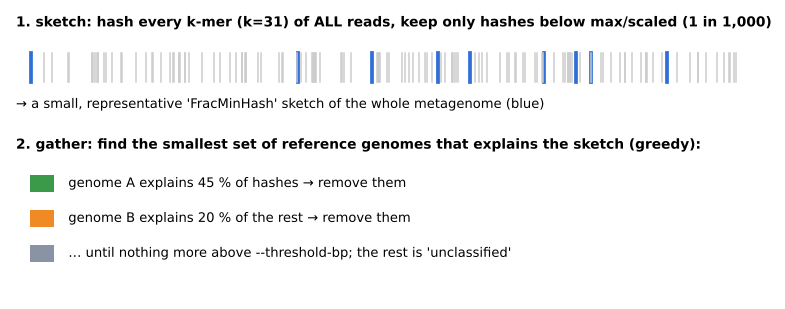<br><em>sourmash works on a down-sampled 'sketch' of all k-mers of the sample and explains it greedily with reference genomes.</em></p>

### Background
[**sourmash**](https://sourmash.readthedocs.io/) is k-mer-based like Kraken, but instead of classifying **reads one at a time** it compares the k-mer content of the **entire dataset** with reference genomes. It can therefore use information that spans many reads (but not information *within* a read, such as its position).

* **Sketching (FracMinHash).** Every k-mer (k = 31) of all reads is hashed; only hashes below `max_hash / scaled` are kept – with `scaled=1000`, roughly **1 in 1,000** k-mers. Because the same k-mer always gives the same hash, sample and reference sketches are directly comparable. `abund` also stores how often each hash occurs.
* **gather.** Finds the **minimum set** of reference genomes that explains the sketch: it picks the genome sharing most hashes with the sample, removes those hashes, and repeats until no genome explains more than `--threshold-bp` base pairs. This greedy approach handles closely related genomes well – each hash is credited to one genome only.
* **tax metagenome.** Sums the gather results up the taxonomy to a chosen rank (phylum, genus, …).

We use the **GTDB rs207 genomic representatives** database: [GTDB](https://gtdb.ecogenomic.org/) is a genome-based bacterial and archaeal taxonomy that differs from NCBI's – names can differ between the tools (e.g. genera split into `Clostridium_A`, `Clostridium_B` …).

```bash
# DO NOT RUN (ALREADY DONE)
# wget https://farm.cse.ucdavis.edu/~ctbrown/sourmash-db/gtdb-rs207/gtdb-rs207.genomic-reps.dna.k31.zip
# wget https://farm.cse.ucdavis.edu/~ctbrown/sourmash-db/gtdb-rs207/gtdb-rs207.taxonomy.with-strain.csv.gz
```

### Sketch and gather

| Command / flag | Meaning |
|---|---|
| `sourmash sketch dna <reads>` | create a DNA sketch |
| `-p k=31,scaled=1000,abund` | **p**arameters: k-mer size 31, keep 1/1000 hashes, track abundances |
| `-o …sig.zip` | output signature file |
| `--merge ${sample}` | merge everything into one signature named after the sample |
| `sourmash gather <sample sig> <database>` | find the genomes that explain the sample |
| `-k 31` | use the k = 31 sketches |
| `--threshold-bp 10` | report matches down to ~10 bp of estimated overlap (very permissive, to see everything) |
| `-o …gather.csv` | save results as CSV |

In [ ]:
%%bash
cd $WORKDIR
for sample in $(cat SAMPLES.txt); do
  echo "$(date +%H:%M:%S)  sourmash: ${sample}"
  sourmash -q sketch dna 04_HOST_REMOVAL/${sample}_unaligned_to_hg38.fastq.gz \
                      -p k=31,scaled=1000,abund \
                      -o 05_TAXONOMIC_PROFILE/${sample}.sig.zip \
                      --merge ${sample}

  sourmash -q gather 05_TAXONOMIC_PROFILE/${sample}.sig.zip $SOURMASH_DB \
                  -k 31 --threshold-bp 10 \
                  -o 05_TAXONOMIC_PROFILE/${sample}.gather.csv > /dev/null
done

`-q` makes sourmash quiet; the gather table printed to the screen is discarded (`> /dev/null`) because we read the CSV instead. Key columns: `name` (matched genome), `f_unique_weighted` (fraction of the sample's **k-mer abundance** uniquely explained by this genome), `intersect_bp` (estimated overlap in bp) and `average_abund`.

In [ ]:
g = pd.read_csv("05_TAXONOMIC_PROFILE/sample10.gather.csv")
g["name"] = g["name"].str.slice(0, 70)
g[["name", "intersect_bp", "f_unique_weighted", "average_abund"]].head(15)

### Summarise per phylum and per genus

`sourmash tax metagenome` adds the GTDB taxonomy to all gather results:
`-g` the gather CSVs of all samples, `-t` the taxonomy file, `--output-format lineage_summary` one table with lineages as rows and samples as columns, `--rank` the rank to summarise at.

In [ ]:
%%bash
cd $WORKDIR
for rank in phylum genus; do
  sourmash -q tax metagenome -g 05_TAXONOMIC_PROFILE/*.gather.csv \
                          -t $SOURMASH_TAX \
                          --output-dir 05_TAXONOMIC_PROFILE \
                          --output-base sourmash.${rank} \
                          --output-format lineage_summary \
                          --rank ${rank}
done
ls 05_TAXONOMIC_PROFILE/sourmash.*

In [ ]:
lin = pd.read_csv(glob.glob("05_TAXONOMIC_PROFILE/sourmash.genus*lineage_summary*")[0], sep="\t", index_col=0)
lin.index = [x.split(";")[-1] for x in lin.index]      # keep only the genus name
top = lin.loc[lin.max(axis=1).sort_values(ascending=False).index[:25]]
display(top.round(3))

plt.figure(figsize=(1.0 * top.shape[1] + 4, 0.35 * top.shape[0] + 2))
plt.imshow(top, aspect="auto", cmap="magma_r")
plt.colorbar(label="fraction of sample (sourmash)")
plt.xticks(range(top.shape[1]), top.columns, rotation=90)
plt.yticks(range(top.shape[0]), top.index, fontsize=8)
plt.title("sourmash: top 25 GTDB genera"); plt.tight_layout(); plt.show()

❓ **Questions**
1. Which genera dominate? Do KrakenUniq and sourmash agree on the main taxa?
2. Is *Yersinia* found by sourmash in sample10? In which other samples?
3. sourmash uses only 1/1000 of all k-mers. What does that mean for organisms present at **very low** abundance – a typical situation for an ancient pathogen?
4. Why might the two tools disagree even for abundant organisms? (Hint: database, taxonomy, read-level vs dataset-level.)

---
## 8. Reference databases: build your own and explore the k-mer size

> This section is new compared to the original course text. It covers the **database construction** and **k-mer size** topics of today's lecture with a database small enough to build in Colab in a few minutes.

### Background: the database decides what you can find
A classifier can only report organisms **that are in its database**. Database choice is therefore one of the most consequential decisions in a metagenomic study:

* **Completeness.** Reads from an organism missing from the database are not simply "unclassified" – if a relative is present, they are assigned to the relative. Small databases (like MiniKraken) produce **confidently wrong** species names.
* **Content quality.** Reference genomes can be contaminated – recall the carp genome with Illumina adapters from Day 1. Day 4 is devoted to this problem.
* **Composition.** Which kingdoms are included (bacteria, archaea, viruses, fungi, plants, animals?) determines which "false friends" are available. For sedimentary aDNA, missing eukaryotes are a major problem.
* **Resources.** Complete databases are large (hundreds of GB for KrakenUniq with all of NCBI nt); minimizers (Kraken2) and sketches (sourmash) are ways to reduce memory.

### Background: what does k change?

The k-mer length is a trade-off between **specificity** and **sensitivity**, and for aDNA the read length and damage make this trade-off especially sharp. Let's calculate three things for different k:

1. **Random matches:** the chance that a random k-mer exists by accident in a database of total size *G* bp is about *G / 4ᵏ*. Short k-mers match by chance.
2. **k-mers per read:** a read of length *L* has *L − k + 1* k-mers; a 35 bp aDNA read has only 5 k-mers at k = 31, and **none** at k = 35.
3. **Damage/error-free k-mers:** if each base has a probability *p* of carrying a damage-induced or sequencing mismatch, a k-mer is error-free with probability *(1 − p)ᵏ*; longer k-mers are hit more often.

In [ ]:
k = np.arange(11, 41)
G = 1e11              # ~100 Gbp: order of magnitude of a large microbial database
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

ax[0].semilogy(k, np.minimum(G / 4.0**k, 1), color="#D93636")
ax[0].set_title("P(random k-mer present in a 100 Gbp DB)"); ax[0].set_xlabel("k")

for L, c in [(35, "#7B4FB0"), (50, "#2E6FD8"), (70, "#3A9A4A")]:
    ax[1].plot(k, np.maximum(L - k + 1, 0), label=f"read {L} bp", color=c)
ax[1].set_title("k-mers per read"); ax[1].set_xlabel("k"); ax[1].legend()

for p, c in [(0.01, "#2E6FD8"), (0.03, "#F08A24"), (0.05, "#D93636")]:
    ax[2].plot(k, (1 - p)**k, label=f"mismatch rate {p:.0%}", color=c)
ax[2].set_title("P(k-mer free of damage/errors)"); ax[2].set_xlabel("k"); ax[2].legend()
for a in ax: a.axvline(31, ls=":", c="k")
plt.tight_layout(); plt.show()

❓ Why do you think k = 31 became the standard choice (dotted line)? What would you lose with k = 21? With k = 41?

### Build two tiny Kraken2 databases

We build two databases from **the same four genomes** that differ only in k (and minimizer length ℓ = k, no spaced seeds, to keep the comparison clean):

| Genome | NCBI taxID | Why it's in the database |
|---|---|---|
| *Yersinia pestis* | 632 | the pathogen in our samples |
| *Yersinia pseudotuberculosis* | 633 | its very close relative (*Y. pestis* evolved from it ~5,000–7,000 years ago) |
| *Escherichia coli* | 562 | another Enterobacteriaceae |
| *Salmonella enterica* | 28901 | another Enterobacteriaceae |

Steps:

1. **Taxonomy.** Kraken2 needs `nodes.dmp` (the tree) and `names.dmp` (the names) from NCBI's `taxdump.tar.gz` in the folder `<db>/taxonomy/`.
2. **Genomes.** Downloaded from the NCBI FTP site with `wget`. Normally Kraken2 maps each sequence to a taxon with huge accession-to-taxID tables; instead, we write the taxID **into each FASTA header** in Kraken2's format `>seqID|kraken:taxid|632`, using `sed` (stream editor): `s/^>\([^ ]*\)/>\1|kraken:taxid|632/` means "on lines starting with `>`, take the sequence ID (everything up to the first space) and append `|kraken:taxid|632`".
3. `kraken2-build --add-to-library <fasta> --db <db> --no-masking` – add each genome to the library; `--no-masking` skips masking of low-complexity regions (which would need an extra tool, `dustmasker`).
4. `kraken2-build --build --db <db> --kmer-len K --minimizer-len L --minimizer-spaces 0` – compute the minimizers and their LCAs and write the hash table.

In [ ]:
%%bash
cd $WORKDIR
mkdir -p 05b_CUSTOM_DB/genomes && cd 05b_CUSTOM_DB

# 1. NCBI taxonomy (names.dmp + nodes.dmp)
wget -q -nc https://ftp.ncbi.nlm.nih.gov/pub/taxonomy/taxdump.tar.gz
tar -xzf taxdump.tar.gz names.dmp nodes.dmp

# 2. genomes: <taxID> <NCBI assembly name>
NCBI=https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF
cat > genomes.txt << EOF
632 GCF_000222975.1_ASM22297v1
633 GCF_000047365.1_ASM4736v1
562 GCF_000005845.2_ASM584v2
28901 GCF_000006945.2_ASM694v2
EOF

while read taxid asm; do
  acc=${asm:4:9}                                     # e.g. 000222975
  dir=$NCBI/${acc:0:3}/${acc:3:3}/${acc:6:3}/${asm}  # NCBI's folder structure: 000/222/975
  wget -q -nc $dir/${asm}_genomic.fna.gz -P genomes/
  zcat genomes/${asm}_genomic.fna.gz | sed "s/^>\([^ ]*\)/>\1|kraken:taxid|${taxid}/" > genomes/${asm}.kraken.fna
  echo "$taxid  $asm  $(grep -c '>' genomes/${asm}.kraken.fna) sequences"
done < genomes.txt
head -n 1 genomes/GCF_000222975.1_ASM22297v1.kraken.fna

A few bash details used above: `cat > file << EOF … EOF` (a *here-document*) writes the lines in between into a file; `while read taxid asm; do … done < genomes.txt` reads the file line by line into two variables; `${asm:4:9}` takes 9 characters starting at position 4 (*substring*), which we use to rebuild NCBI's folder path.

Now build the two databases (each takes a minute or two):

In [ ]:
%%bash
cd $WORKDIR/05b_CUSTOM_DB
for K in 21 31; do
  DB=db_k${K}
  rm -rf $DB && mkdir -p $DB/taxonomy
  cp names.dmp nodes.dmp $DB/taxonomy/
  for f in genomes/*.kraken.fna; do
    kraken2-build --add-to-library $f --db $DB --no-masking > /dev/null
  done
  echo "Building $DB ..."
  kraken2-build --build --db $DB --kmer-len $K --minimizer-len $K --minimizer-spaces 0 \
                --threads $THREADS > $DB.build.log 2>&1
  tail -n 2 $DB.build.log
  kraken2-inspect --db $DB | head -n 6
done

`kraken2-inspect` shows what is in a database: number of minimizers and how they are distributed over the taxonomy. Many minimizers sit above the species level – the k-mers shared by *Y. pestis* and *Y. pseudotuberculosis* go to their LCA, which in the current NCBI taxonomy is the *Yersinia pseudotuberculosis* complex (between species and genus). k-mers shared with *E. coli* and *Salmonella* go to the order Enterobacterales.

### Classify sample10 with both databases

In [ ]:
%%bash
cd $WORKDIR
for K in 21 31; do
  kraken2 --db 05b_CUSTOM_DB/db_k${K} --threads $THREADS --report-minimizer-data \
          --report 05b_CUSTOM_DB/sample10_k${K}.report --output /dev/null \
          04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz 2>&1 | tail -n 2
done

In [ ]:
res = {}
for K in [21, 31]:
    r = read_kraken2(f"05b_CUSTOM_DB/sample10_k{K}.report")
    res[f"k={K}"] = r.groupby("taxName")["taxReads"].sum()
res = pd.DataFrame(res).fillna(0).astype(int)
res = res[(res > 0).any(axis=1)].sort_values("k=31", ascending=False)
display(res)

res.drop("unclassified", errors="ignore").plot.barh(figsize=(9, 0.4 * len(res) + 1.5), color=["#F08A24", "#2E6FD8"])
plt.xlabel("reads assigned directly to the taxon (log scale)"); plt.xscale("symlog")
plt.title("sample10 classified with a 4-genome database"); plt.gca().invert_yaxis(); plt.show()

❓ **Questions**
1. Which database classifies more reads? Are those extra reads likely to be correct, given that the database contains only 4 genomes while sample10 contains many more organisms?
2. How many reads go to *Y. pestis* vs. the *Y. pseudotuberculosis* complex or the genus *Yersinia*? Why are so many reads classified only above the species level?
3. Reads of *E. coli*, *Salmonella* or *Y. pseudotuberculosis* in this tiny-database result: are these organisms really in sample10? (Compare with the KrakenUniq result in Section 3.) What does this tell you about using small databases?
4. Based on this experiment, why do aDNA pipelines use the largest database they can afford – and then still filter on breadth of coverage?

---
## 9. From a k-mer hit to reads on a genome (preview of Day 3)

A k-mer classifier never aligns reads, so the final word on a hit always comes from an **alignment**: are the reads spread evenly over the whole genome, or piled up in a few places?

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/IGV_uneven_coverage_Y.pestis.png" width="720"><br><em>A false-positive Y. pestis hit in IGV: thousands of reads, but all stacked on a few conserved loci.</em></p>

Let's align the human-free reads of sample10 to the *Y. pestis* genome we just downloaded and look at them in IGV. Tomorrow we will turn this picture into numbers (breadth and evenness of coverage, edit distance, damage).

* `gunzip -c … > ypestis.fna` – unpacked reference; `samtools faidx` creates the `.fai` index IGV needs,
* `bowtie2-build` – build the Bowtie2 index (seconds for a 4.6 Mbp genome),
* `bowtie2 … -U <reads> | samtools view -b -q 1` – align, keep reads with **mapping quality ≥ 1** (`-q 1` removes reads that map equally well to several places, MAPQ = 0),
* `samtools sort` + `samtools index` – sorted, indexed BAM,
* `samtools coverage` – per-sequence summary: number of reads, **% of the genome covered** (`coverage`), mean depth.

In [ ]:
%%bash
cd $WORKDIR
mkdir -p 05c_YPESTIS_ALIGNMENT && cd 05c_YPESTIS_ALIGNMENT
gunzip -c ../05b_CUSTOM_DB/genomes/GCF_000222975.1_ASM22297v1_genomic.fna.gz > ypestis.fna
samtools faidx ypestis.fna
bowtie2-build --threads $THREADS ypestis.fna ypestis.fna > /dev/null

bowtie2 -x ypestis.fna --end-to-end --very-sensitive --threads $THREADS \
        -U ../04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz 2> bowtie2.log \
  | samtools view -b -q 1 -@ $THREADS - | samtools sort -@ $THREADS -o sample10_vs_ypestis.bam
samtools index sample10_vs_ypestis.bam

samtools coverage sample10_vs_ypestis.bam

In IGV we load **our own reference genome** (not one of IGV's built-in genomes): `"reference": {"fastaPath": …, "indexPath": …}` points to the local FASTA file and its `.fai` index. We start at the first 20 kb of the chromosome – zoom out to see the whole chromosome and judge whether the reads are spread evenly. Click a read to see its details, and look for **red T's** (C→T mismatches) near read ends.

In [ ]:
import igv_notebook
igv_notebook.init()

aln = f"{WORKDIR}/05c_YPESTIS_ALIGNMENT"
chrom = open(f"{aln}/ypestis.fna.fai").readline().split("\t")[0]
b = igv_notebook.Browser({
    "reference": {"id": "ypestis", "name": "Yersinia pestis",
                  "fastaPath": f"{aln}/ypestis.fna", "indexPath": f"{aln}/ypestis.fna.fai"},
    "locus": f"{chrom}:1-20000"})
b.load_track({"name": "sample10 reads", "path": f"{aln}/sample10_vs_ypestis.bam",
              "indexPath": f"{aln}/sample10_vs_ypestis.bam.bai", "format": "bam", "type": "alignment"})

❓ Does the coverage look like the left (true-positive) or the right (false-positive) picture in Section 2? What fraction of the chromosome is covered according to `samtools coverage`, and why is it low even for a true hit?

---
## Summary

Today we learned that:

* **k-mer classifiers** (KrakenUniq, Kraken2) assign each read to the **LCA**-based best taxon by exact k-mer lookups – fast enough to screen against all known microbes, but without alignment details,
* the number of assigned reads (**depth**) alone produces many false positives; **unique k-mers** (KrakenUniq) or **distinct minimizers** (Kraken2) measure **breadth** of coverage, and filtering on **both** (≥ 200 reads, ≥ 1000 unique k-mers) removes most of them,
* an **abundance matrix** of filtered species is the basis for comparing samples; Krona and Pavian help explore profiles,
* **sourmash** profiles the whole dataset with FracMinHash sketches and the GTDB taxonomy – a complementary view with different strengths and biases,
* the **database** determines what can be found and how wrong the answer can be; **k** trades specificity against sensitivity, which matters a lot for short, damaged aDNA reads,
* every promising hit must be followed up with **alignments** (Day 3).

**Results kept in your Drive for the coming days:** `05_TAXONOMIC_PROFILE/` (reports), `06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt` (used again on Day 4 for decontamination and source tracking), `05c_YPESTIS_ALIGNMENT/` (Day 3).

## Questions to think about
1. What is the difference between depth, breadth and evenness of coverage?
2. Why does a k-mer classifier report an organism that is not in the sample? Give three reasons.
3. When would you prefer sourmash over Kraken-type classifiers, and vice versa?
4. How would you choose a database for a sedimentary aDNA project from a lake versus for dental calculus?
5. How does aDNA damage affect k-mer-based classification, and how does the choice of k interact with it?

## Resources
* KrakenUniq: Breitwieser F.P., Baker D.N., Salzberg S.L. (2018) *Genome Biology* 19:198, [doi:10.1186/s13059-018-1568-0](https://doi.org/10.1186/s13059-018-1568-0)
* Kraken2: Wood D.E., Lu J., Langmead B. (2019) *Genome Biology* 20:257, [doi:10.1186/s13059-019-1891-0](https://doi.org/10.1186/s13059-019-1891-0)
* sourmash: Irber L. et al. (2022) Lightweight compositional analysis of metagenomes with FracMinHash and minimum metagenome covers, [doi:10.1101/2022.01.11.475838](https://doi.org/10.1101/2022.01.11.475838)
* Krona: Ondov B.D., Bergman N.H., Phillippy A.M. (2011) *BMC Bioinformatics* 12:385, [doi:10.1186/1471-2105-12-385](https://doi.org/10.1186/1471-2105-12-385)
* Pavian: Breitwieser F.P., Salzberg S.L. (2020) *Bioinformatics* 36:1303–1304, [github.com/fbreitwieser/pavian](https://github.com/fbreitwieser/pavian)
* GTDB: [gtdb.ecogenomic.org](https://gtdb.ecogenomic.org/)
* aMeta: Pochon Z. et al. (2023), [doi:10.1101/2022.10.03.510579](https://doi.org/10.1101/2022.10.03.510579)